# Group A: Scatter plots broken out by Grade Level

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
import os

# --- Paths ---
elpac_dir = "../1095 Data/ELPAC/"
enrollment_dir = "../1095 Data/Enrollment"
group_csv = "group_a_ssids.csv"

# --- Load Group A SSIDs ---
group_a_ssids = set(pd.read_csv(group_csv)["SSID"])
print(f"Group A: {len(group_a_ssids):,} students")

# --- Load Enrollment files and combine ---
enrollment_files = {
    "2021-22": "CEnrollment_21-22.csv",
    "2022-23": "CEnrollment_22-23.csv",
    "2023-24": "CEnrollment_23-24.csv",
}

enrollments = {}
for label, filename in enrollment_files.items():
    enrollments[label] = pd.read_csv(os.path.join(enrollment_dir, filename), low_memory=False)

enrollment_all = pd.concat(enrollments.values(), ignore_index=True)
enrollment_all = enrollment_all.drop_duplicates(subset="SSID", keep="first")
enrollment_a = enrollment_all[enrollment_all["SSID"].isin(group_a_ssids)]
print(f"Group A enrollment records: {len(enrollment_a):,}")

# --- Load Initial ELPAC files ---
initial_files = {
    "Initial 2022": "InitialElpac_22.csv",
    "Initial 2023": "InitialElpac_23.csv",
    "Initial 2024": "InitialElpac_24.csv",
}

initial_dfs = {}
for label, filename in initial_files.items():
    df = pd.read_csv(os.path.join(elpac_dir, filename))
    df = df.apply(lambda col: col.str.strip() if col.dtype == "object" else col)
    df["TestStartDate"] = pd.to_datetime(df["TestStartDate"], errors="coerce")
    initial_dfs[label] = df

# --- Load Summative ELPAC files ---
summative_files = {
    1: "SummativeElpac_22.csv",
    2: "SummativeElpac_23.csv",
    3: "SummativeElpac_24.csv",
}

summative_dfs = {}
for year_num, filename in summative_files.items():
    df = pd.read_csv(os.path.join(elpac_dir, filename))
    df = df.apply(lambda col: col.str.strip() if col.dtype == "object" else col)
    df["OverallScaleScore"] = pd.to_numeric(df["OverallScaleScore"], errors="coerce")
    df["TestStartDate"] = pd.to_datetime(df["TestStartDate"], errors="coerce")
    summative_dfs[year_num] = df

# --- Find earliest initial test date per student ---
first_initial_date = {}
for label, df in initial_dfs.items():
    df_group = df[df["SSID"].isin(group_a_ssids)][["SSID", "TestStartDate"]].dropna()
    for _, row in df_group.iterrows():
        ssid = row["SSID"]
        if ssid not in first_initial_date or row["TestStartDate"] < first_initial_date[ssid]:
            first_initial_date[ssid] = row["TestStartDate"]

print(f"Students with an initial test date: {len(first_initial_date):,}")

# --- Build summative year counts to identify students with all 3 summative scores ---
summative_year_count = {}
for year_num, df in summative_dfs.items():
    for ssid in df["SSID"].dropna().unique():
        summative_year_count[ssid] = summative_year_count.get(ssid, 0) + 1

complete_ssids = {
    ssid for ssid in group_a_ssids
    if summative_year_count.get(ssid, 0) == 3
}
print(f"Group A students with all 3 summative scores: {len(complete_ssids):,}")

# --- Build full scatter dataset (x = days since first initial, y = OverallScaleScore) ---
records = []
for year_num, df in summative_dfs.items():
    df_group = df[df["SSID"].isin(complete_ssids)].dropna(
        subset=["OverallScaleScore", "TestStartDate"]
    )
    for _, row in df_group.iterrows():
        ssid = row["SSID"]
        if ssid in first_initial_date:
            days = (row["TestStartDate"] - first_initial_date[ssid]).days
            records.append({"SSID": ssid, "days": days, "score": row["OverallScaleScore"]})

scatter_df = pd.DataFrame(records)

# --- Apply filters: x > 0 and y > 1000 ---
scatter_df = scatter_df[(scatter_df["days"] > 0) & (scatter_df["score"] > 1000)]
print(f"Filtered scatter points (x > 0, y > 1000): {len(scatter_df):,}")

# --- Merge in grade level from enrollment ---
scatter_df = scatter_df.merge(
    enrollment_a[["SSID", "GradeLevelCode"]].dropna(),
    on="SSID", how="left"
)

# --- Global y-axis max ---
y_max = scatter_df["score"].max() * 1.10
print(f"Global max score: {scatter_df['score'].max():.1f}, y-axis ceiling: {y_max:.1f}")

# --- Get sorted unique grade levels ---
grade_levels = sorted(scatter_df["GradeLevelCode"].dropna().unique())
print(f"\nGrade levels found: {grade_levels}")

Group A: 30,779 students
Group A enrollment records: 30,779
Students with an initial test date: 30,708
Group A students with all 3 summative scores: 30,779
Filtered scatter points (x > 0, y > 1000): 97,235
Global max score: 1829.0, y-axis ceiling: 2011.9

Grade levels found: ['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12', 'KN', 'PS']


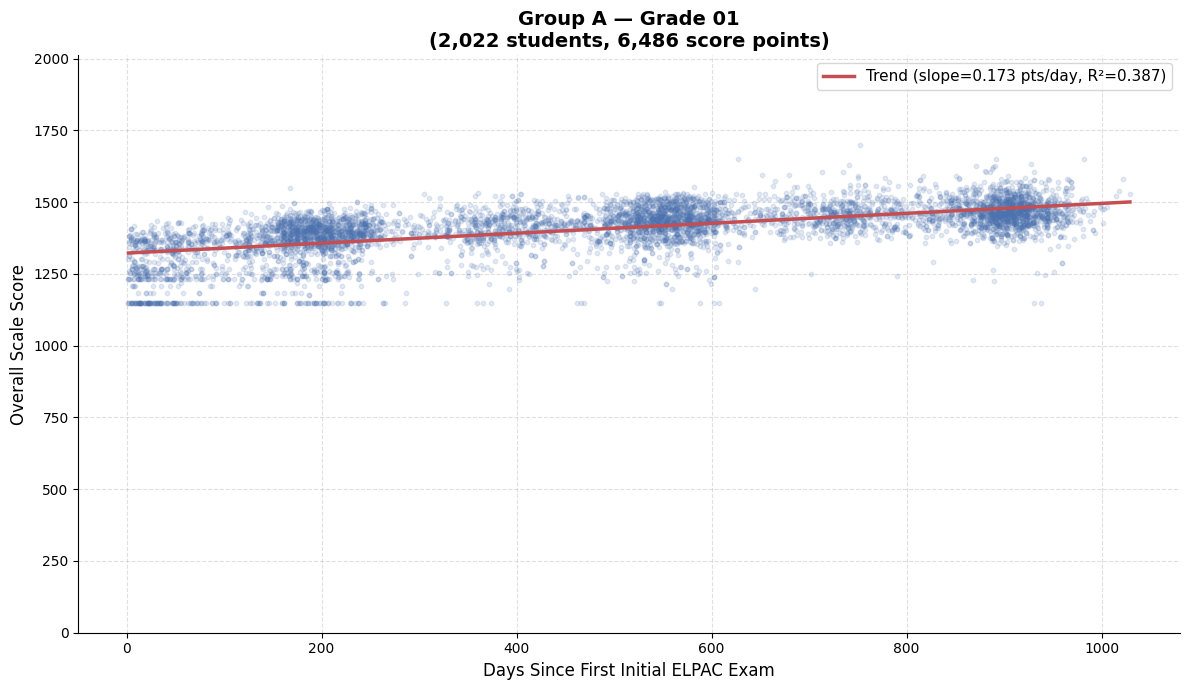

Saved: group_a_grade_01_scatter.png


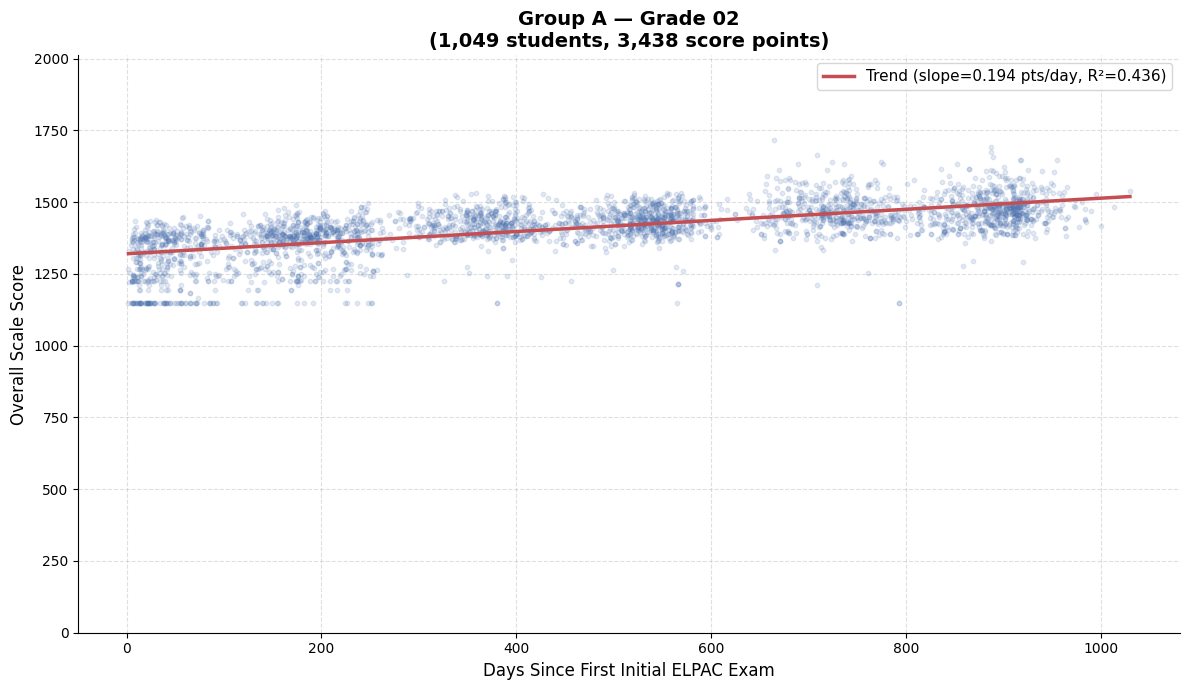

Saved: group_a_grade_02_scatter.png


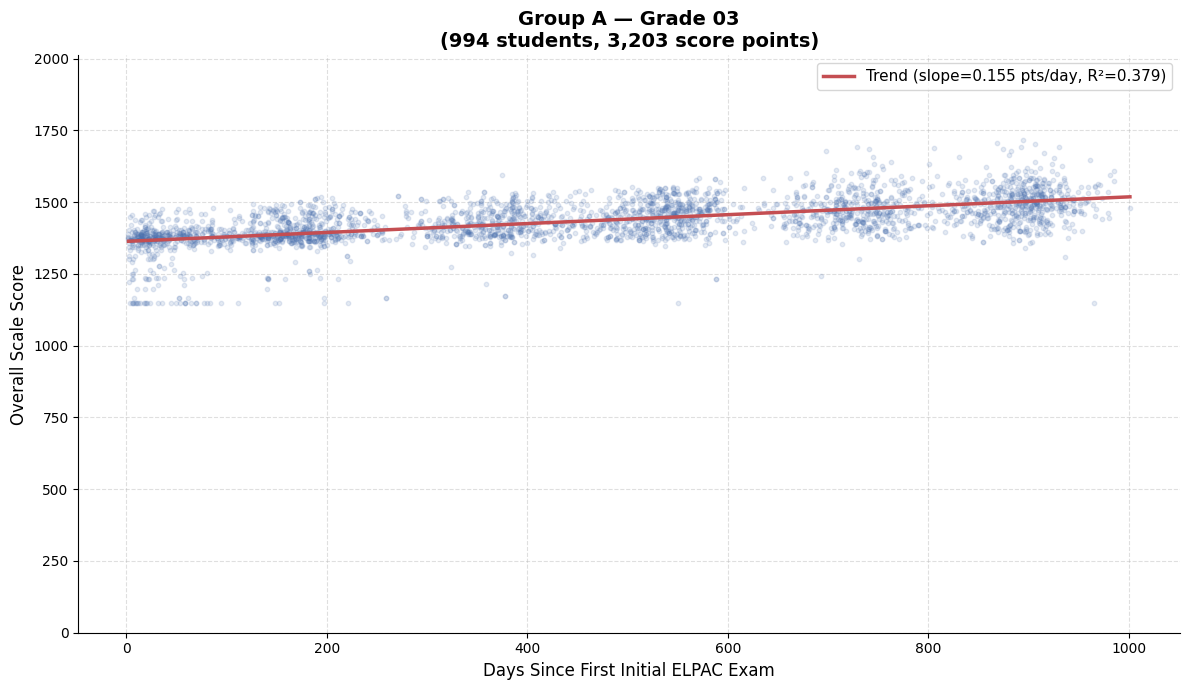

Saved: group_a_grade_03_scatter.png


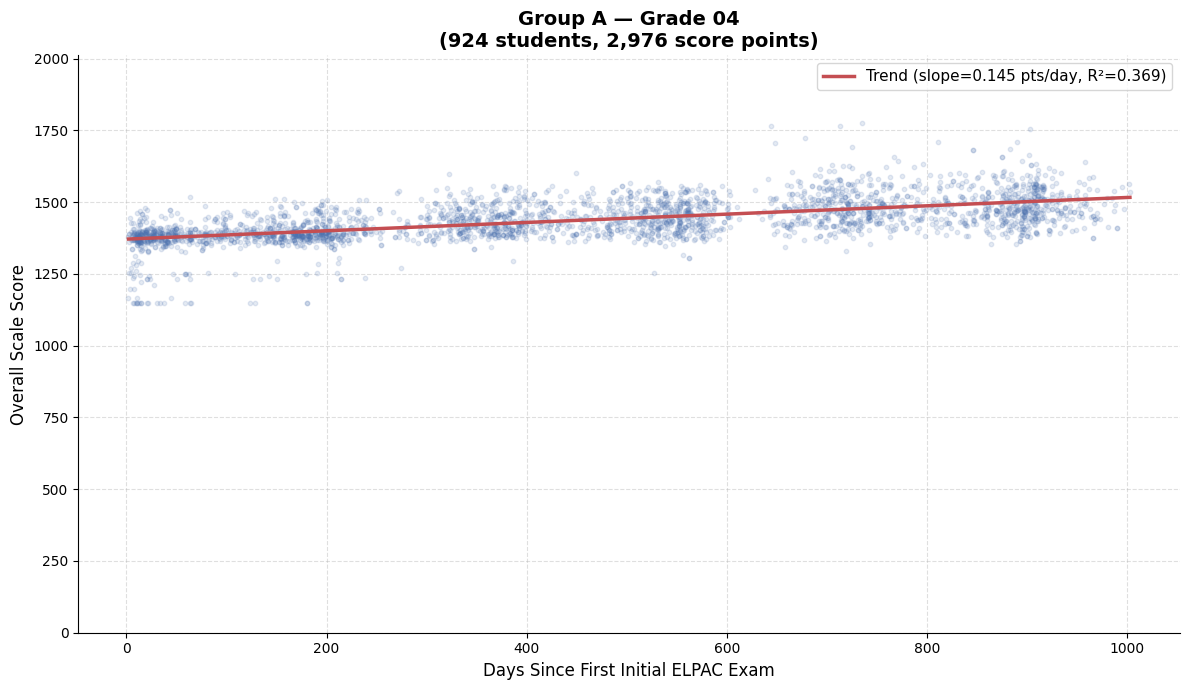

Saved: group_a_grade_04_scatter.png


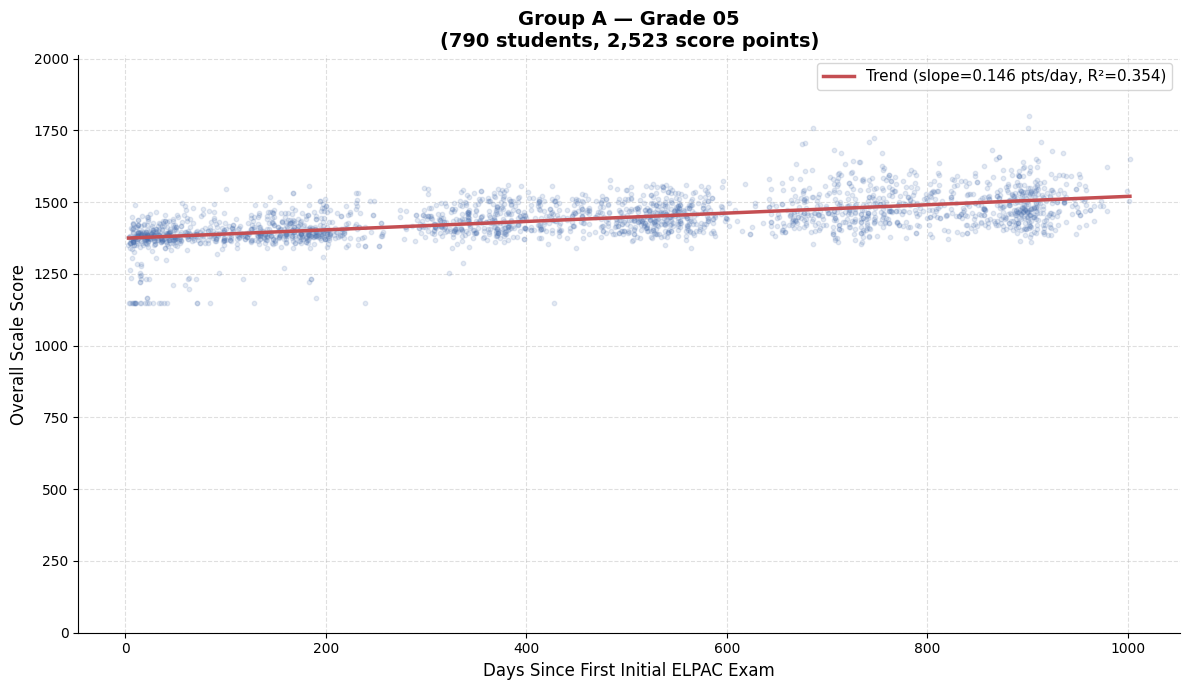

Saved: group_a_grade_05_scatter.png


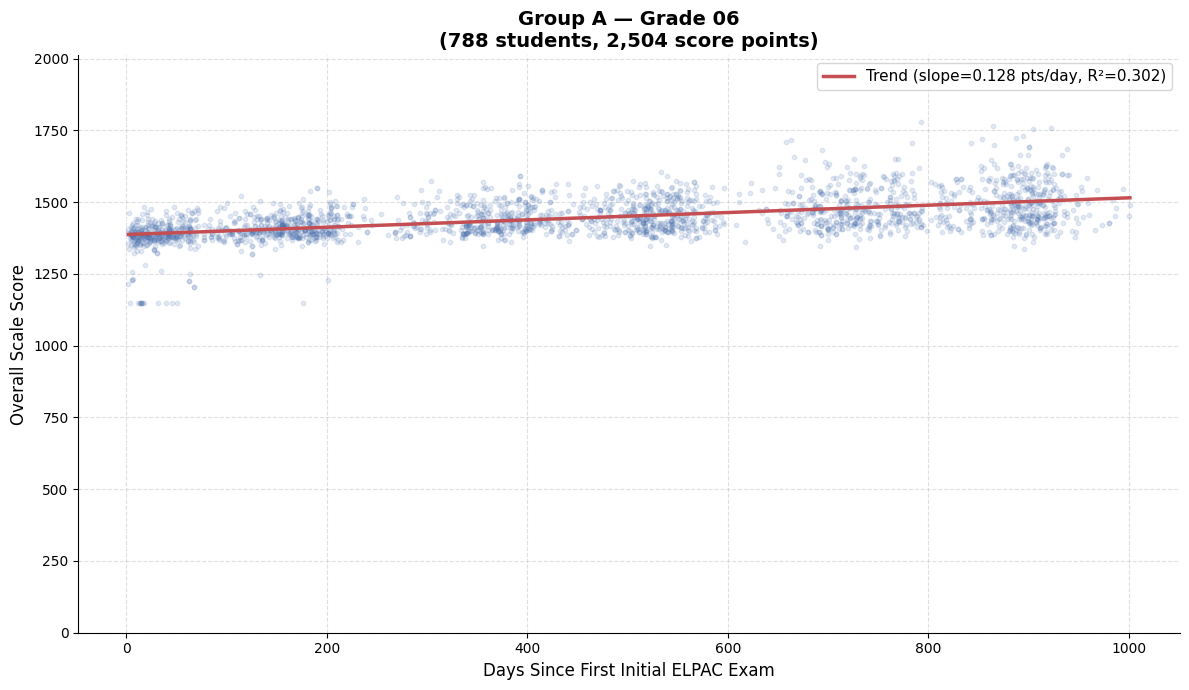

Saved: group_a_grade_06_scatter.png


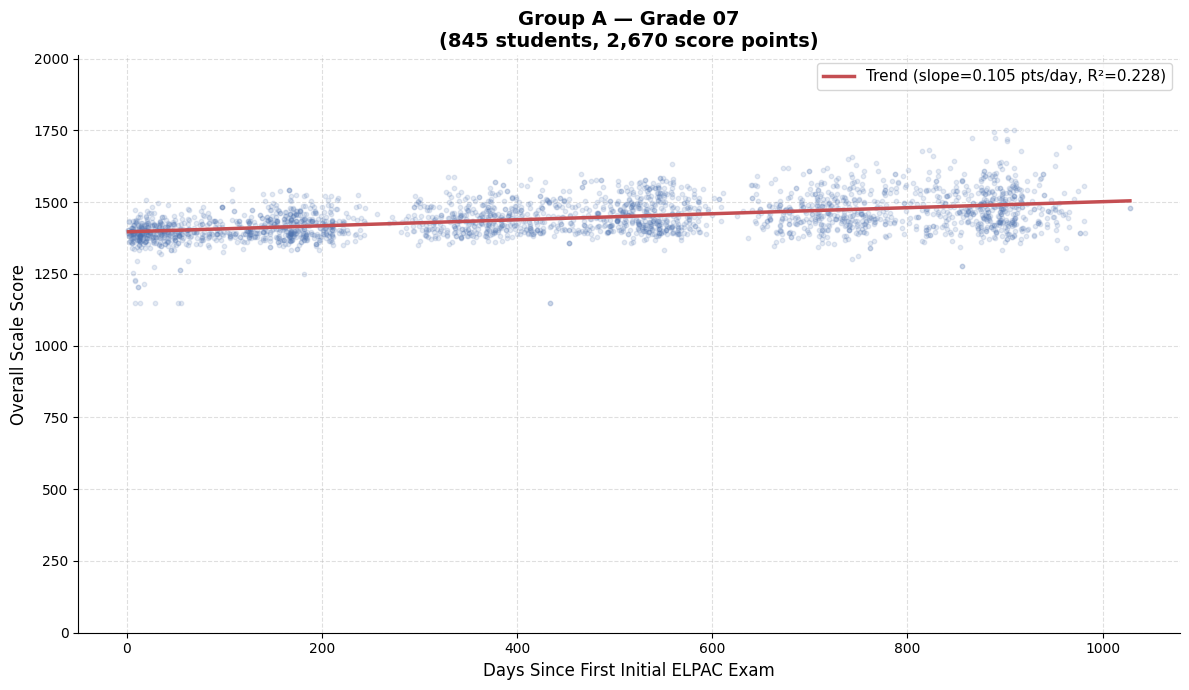

Saved: group_a_grade_07_scatter.png


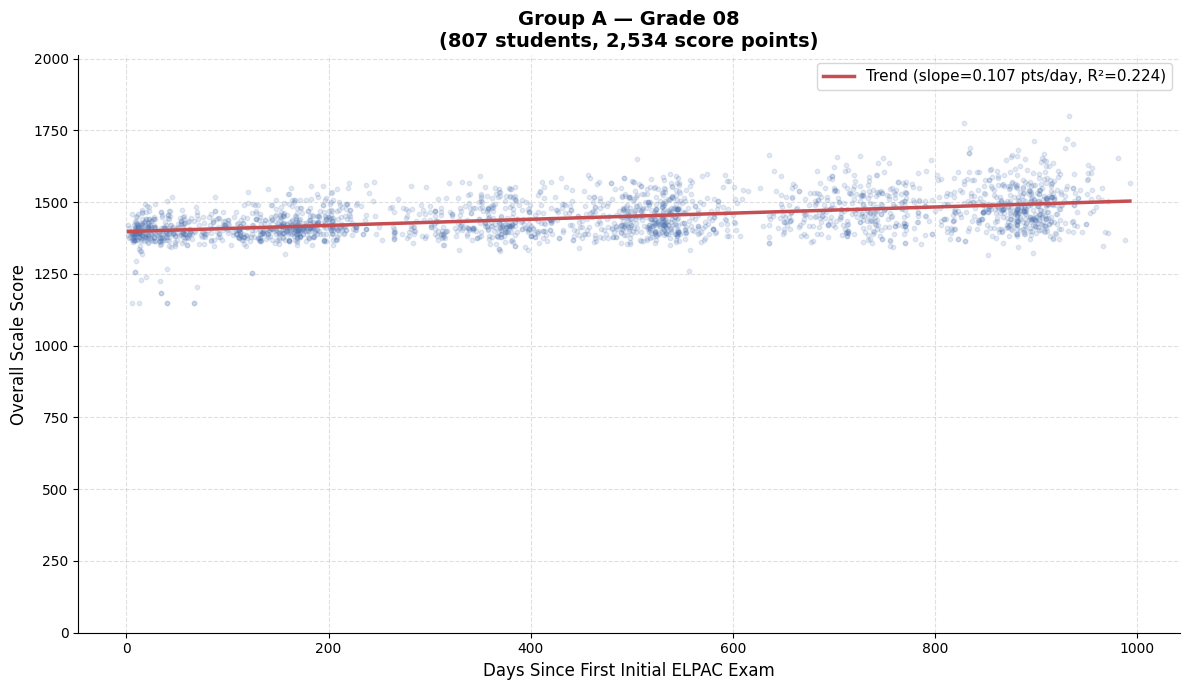

Saved: group_a_grade_08_scatter.png


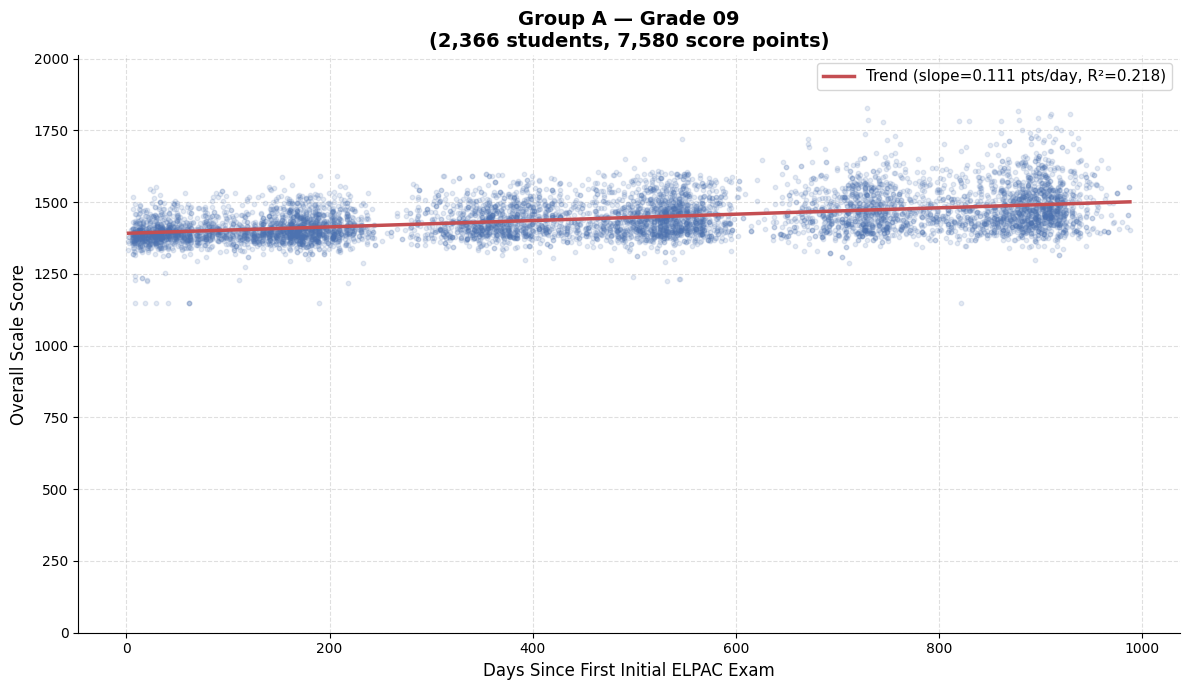

Saved: group_a_grade_09_scatter.png


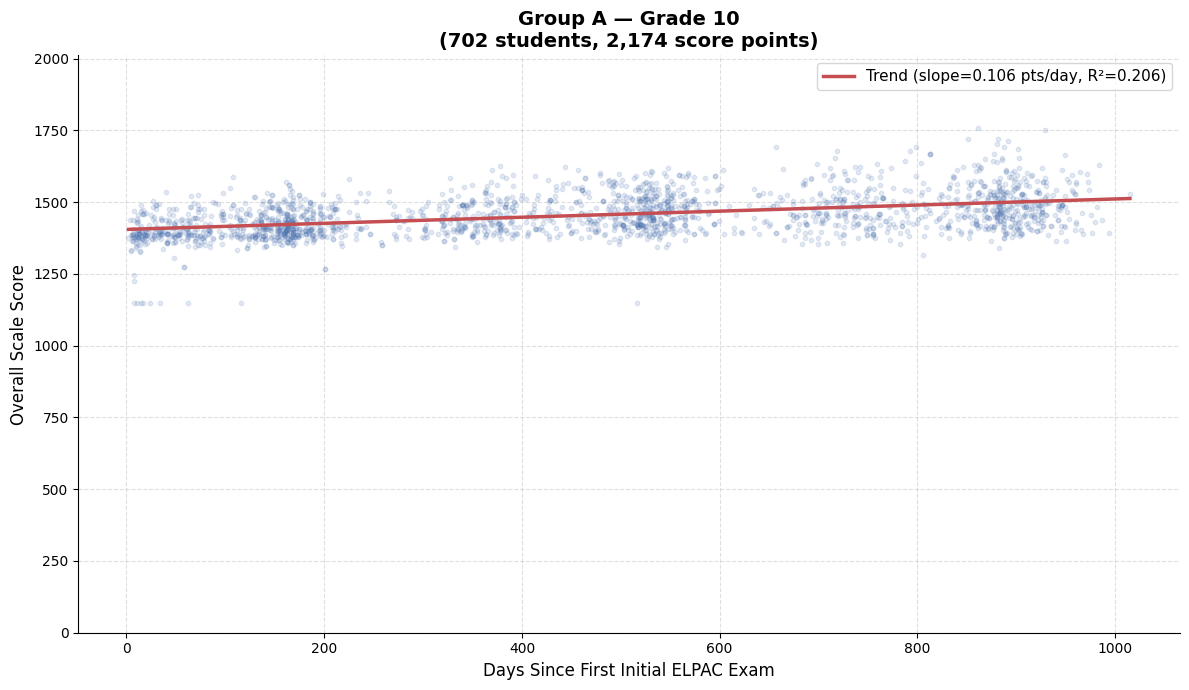

Saved: group_a_grade_10_scatter.png


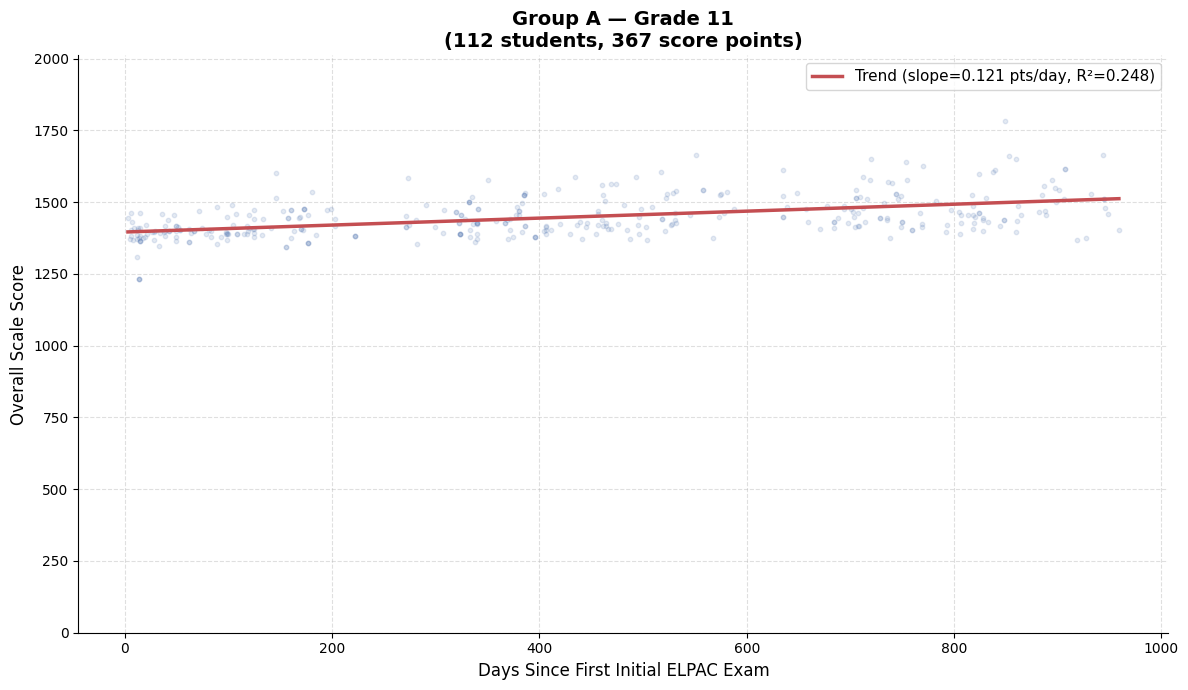

Saved: group_a_grade_11_scatter.png


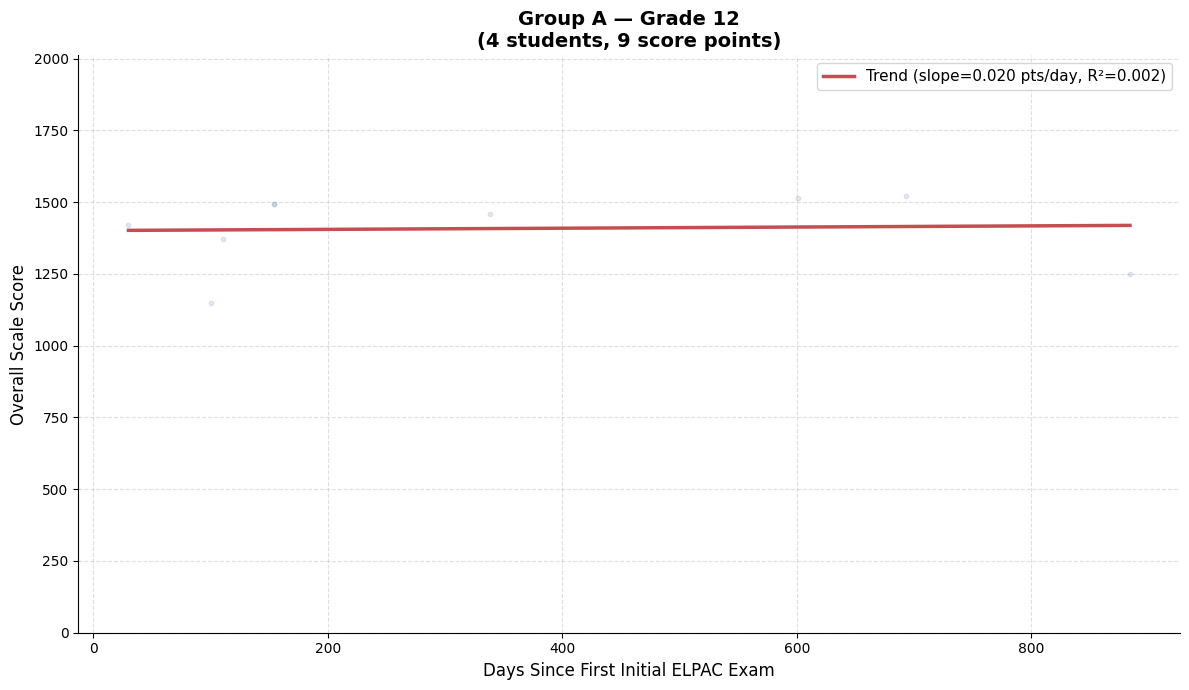

Saved: group_a_grade_12_scatter.png


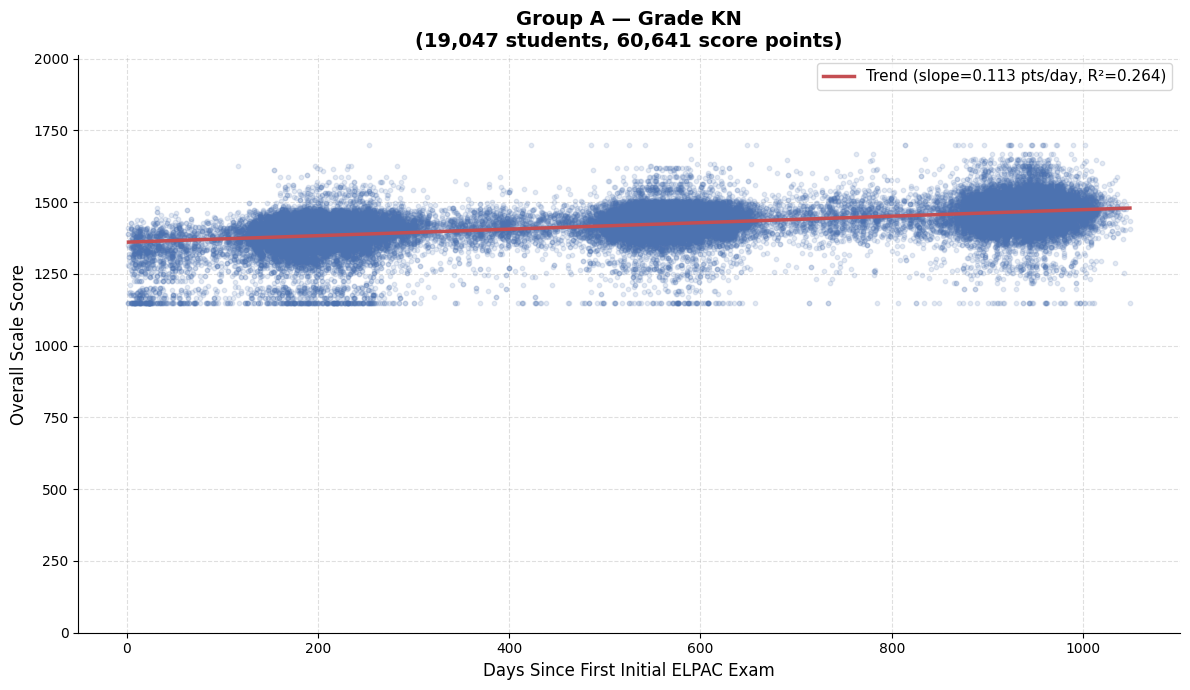

Saved: group_a_grade_KN_scatter.png


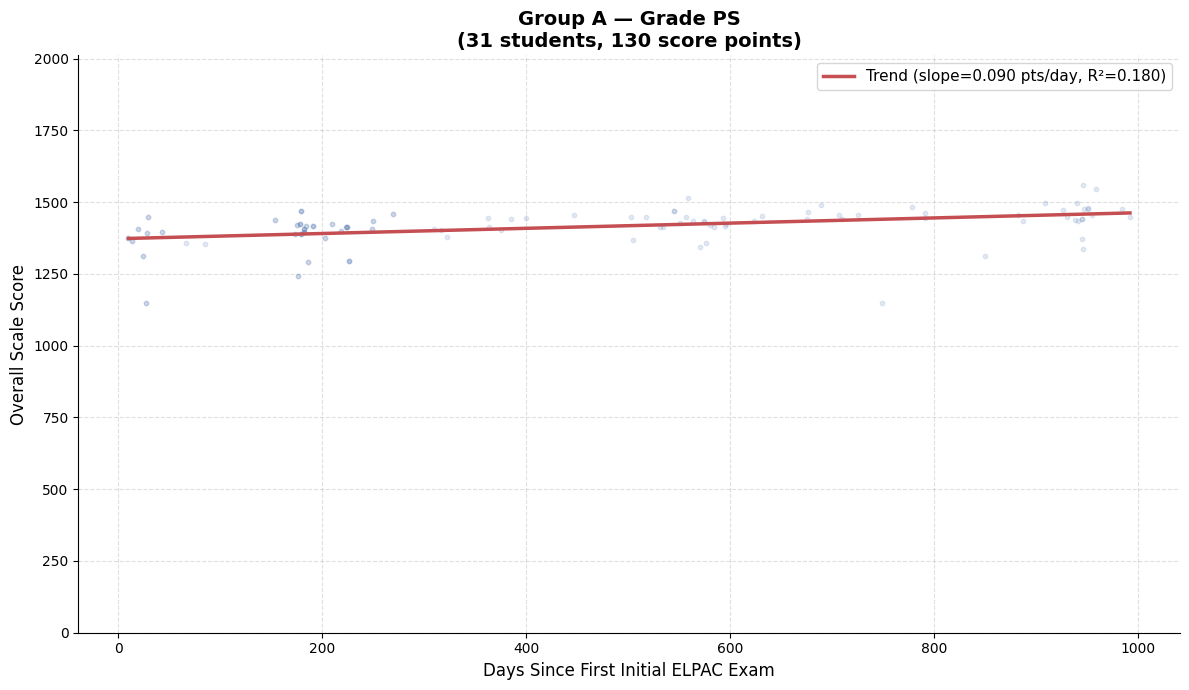

Saved: group_a_grade_PS_scatter.png


In [2]:
# --- One scatter plot per grade level ---
for grade in grade_levels:
    grade_data = scatter_df[scatter_df["GradeLevelCode"] == grade]
    x = grade_data["days"].values
    y = grade_data["score"].values

    if len(x) < 2:
        print(f"Skipping grade {grade} — insufficient data ({len(x)} points)")
        continue

    fig, ax = plt.subplots(figsize=(12, 7))

    ax.scatter(x, y, color="#4C72B0", alpha=0.15, s=10, zorder=2)

    # Trend line + R²
    slope, intercept, r_value, _, _ = stats.linregress(x, y)
    trend_x = np.linspace(x.min(), x.max(), 300)
    trend_y = slope * trend_x + intercept
    r_squared = r_value ** 2
    ax.plot(trend_x, trend_y, color="#C44E52", linewidth=2.5, zorder=3,
            label=f"Trend (slope={slope:.3f} pts/day, R²={r_squared:.3f})")

    ax.set_ylim(0, y_max)
    ax.set_xlabel("Days Since First Initial ELPAC Exam", fontsize=12)
    ax.set_ylabel("Overall Scale Score", fontsize=12)
    ax.set_title(f"Group A — Grade {grade}\n"
                 f"({grade_data['SSID'].nunique():,} students, {len(x):,} score points)",
                 fontsize=14, fontweight="bold")
    ax.legend(fontsize=11)
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.spines[["top", "right"]].set_visible(False)

    plt.tight_layout()
    output_file = f"plots/group_a_grade_{grade}_scatter.png"
    plt.savefig(output_file, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: {output_file}")

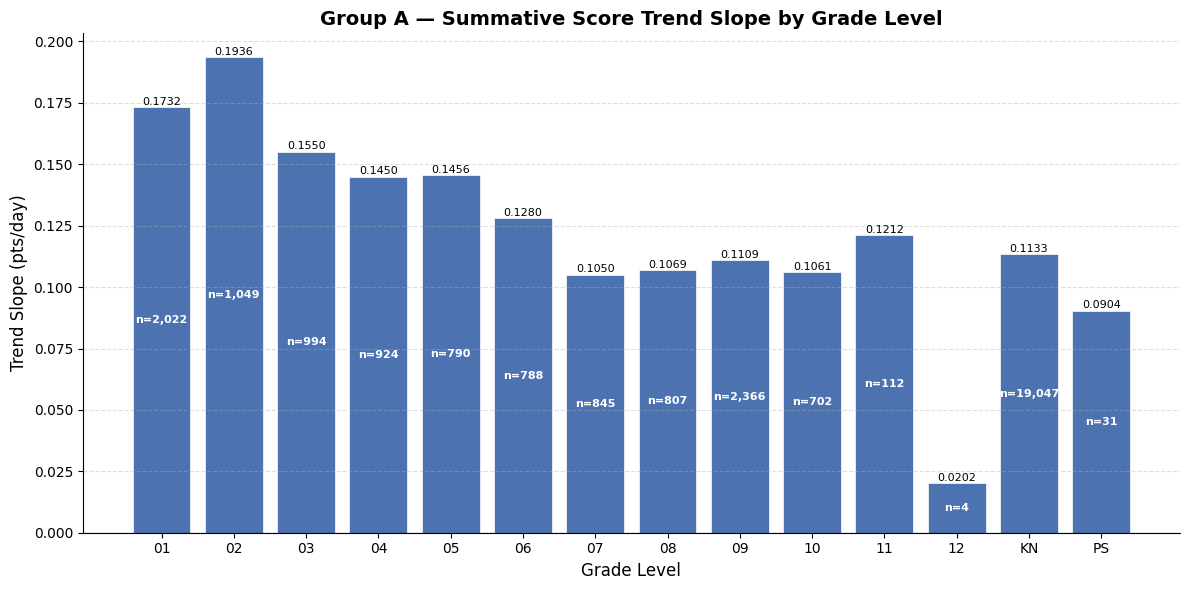

Saved: plots/group_a_slope_by_grade.png


In [4]:
# --- Compute slope and student count per grade level ---
grade_slopes = {}
grade_counts = {}
for grade in grade_levels:
    grade_data = scatter_df[scatter_df["GradeLevelCode"] == grade]
    x = grade_data["days"].values
    y = grade_data["score"].values
    if len(x) < 2:
        continue
    slope, _, _, _, _ = stats.linregress(x, y)
    grade_slopes[grade] = slope
    grade_counts[grade] = grade_data["SSID"].nunique()

grades = list(grade_slopes.keys())
slopes = list(grade_slopes.values())
counts = [grade_counts[g] for g in grades]

# --- Bar chart ---
os.makedirs("plots", exist_ok=True)

fig, ax = plt.subplots(figsize=(12, 6))

colors = ["#4C72B0" if s >= 0 else "#C44E52" for s in slopes]
bars = ax.bar(grades, slopes, color=colors, edgecolor="white", linewidth=0.5)

# Slope label on top/bottom of each bar
for bar, slope in zip(bars, slopes):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + (0.0002 if slope >= 0 else -0.0002),
        f"{slope:.4f}",
        ha="center",
        va="bottom" if slope >= 0 else "top",
        fontsize=8
    )

# Student count overlaid in the middle of each bar
for bar, count, slope in zip(bars, counts, slopes):
    bar_mid = bar.get_height() / 2
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar_mid,
        f"n={count:,}",
        ha="center",
        va="center",
        fontsize=8,
        color="white",
        fontweight="bold"
    )

ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
ax.set_xlabel("Grade Level", fontsize=12)
ax.set_ylabel("Trend Slope (pts/day)", fontsize=12)
ax.set_title("Group A — Summative Score Trend Slope by Grade Level", fontsize=14, fontweight="bold")
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("plots/group_a_slope_by_grade.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: plots/group_a_slope_by_grade.png")

In [9]:
# --- Map grade levels to school groups ---
grade_group_map = {
    "KN": "Elementary", "01": "Elementary", "02": "Elementary",
    "03": "Elementary", "04": "Elementary", "05": "Elementary",
    "06": "Middle School", "07": "Middle School", "08": "Middle School",
    "09": "High School", "10": "High School", "11": "High School", "12": "High School",
}

scatter_df["SchoolGroup"] = scatter_df["GradeLevelCode"].map(grade_group_map)

# Drop PS and any unmapped grades
scatter_df_grouped = scatter_df[scatter_df["SchoolGroup"].notna()].copy()

group_order = ["Elementary", "Middle School", "High School"]
print("Students per school group:")
for group in group_order:
    g = scatter_df_grouped[scatter_df_grouped["SchoolGroup"] == group]
    print(f"  {group}: {g['SSID'].nunique():,} students, {len(g):,} score points")

Students per school group:
  Elementary: 24,826 students, 79,267 score points
  Middle School: 2,440 students, 7,708 score points
  High School: 3,184 students, 10,130 score points


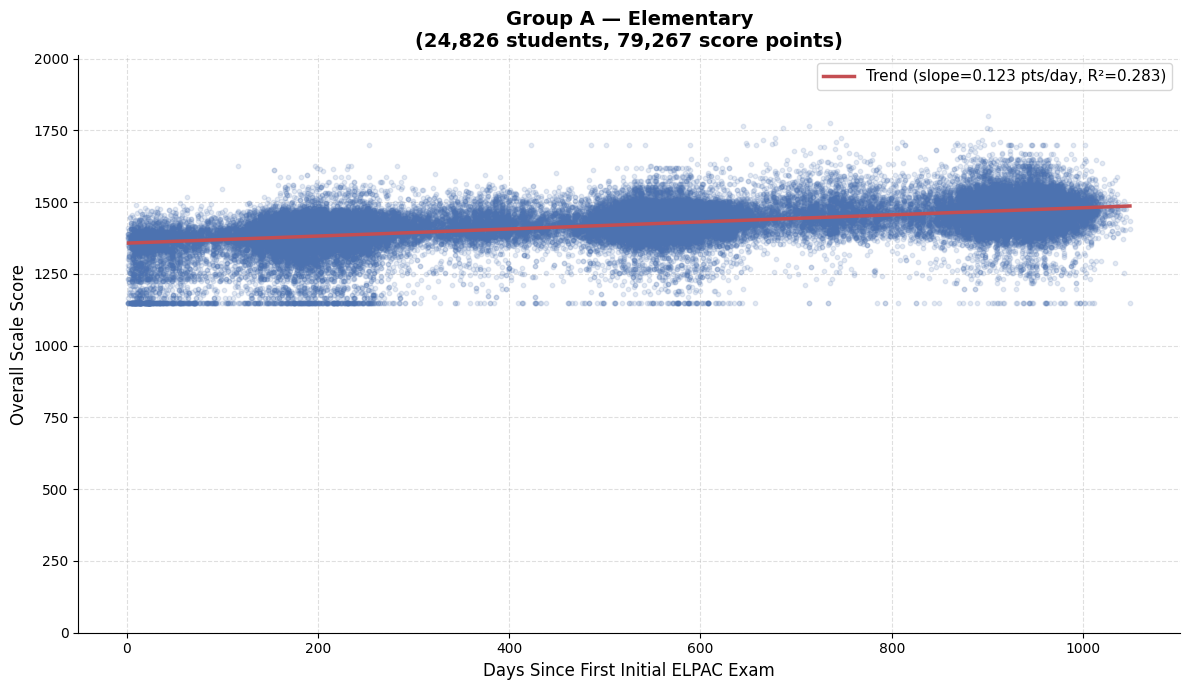

Saved: plots/group_a_elementary_scatter.png


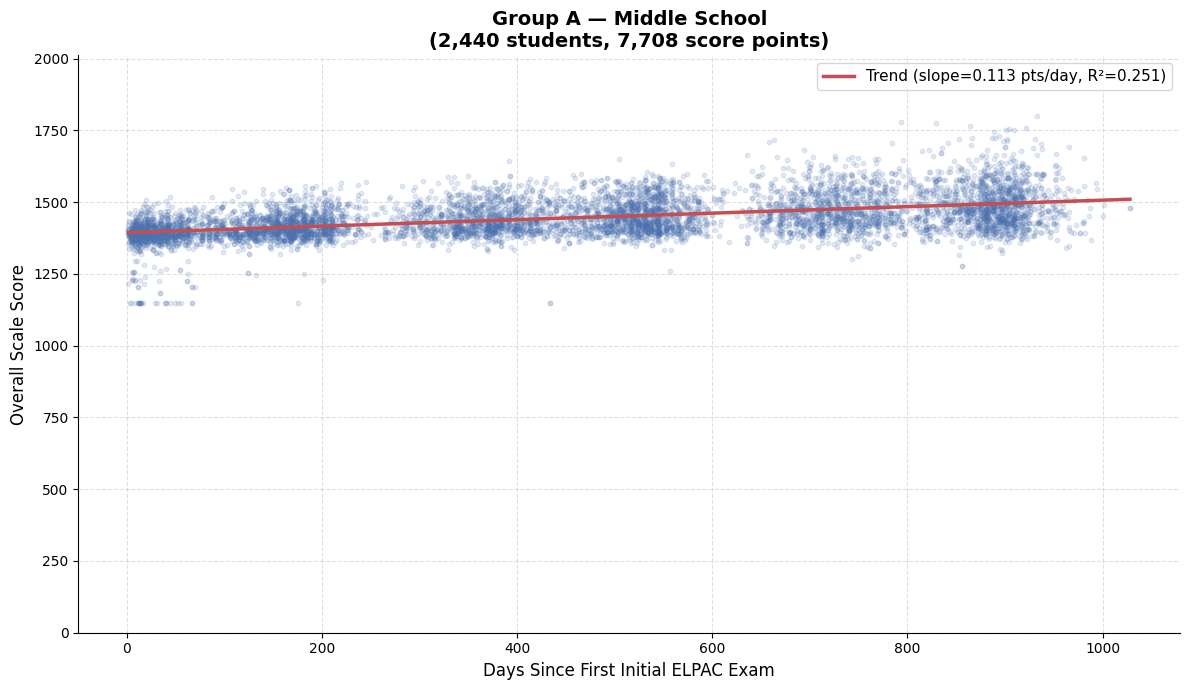

Saved: plots/group_a_middle_school_scatter.png


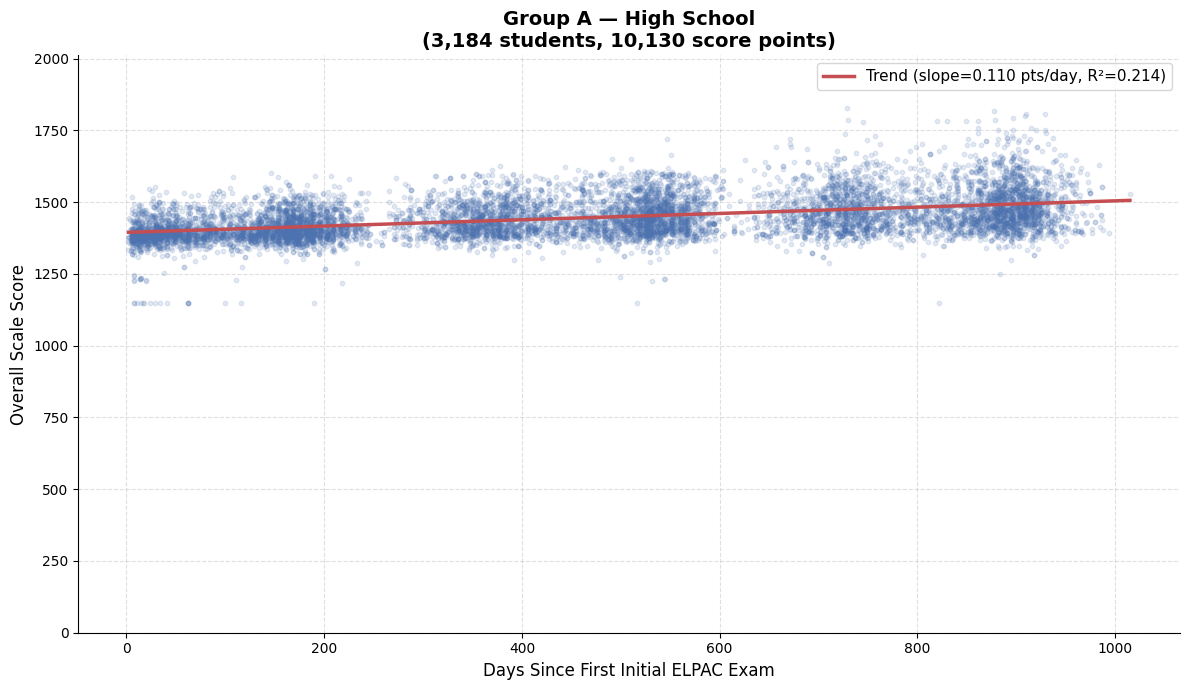

Saved: plots/group_a_high_school_scatter.png


In [10]:
# --- One scatter plot per school group ---
for group in group_order:
    group_data = scatter_df_grouped[scatter_df_grouped["SchoolGroup"] == group]
    x = group_data["days"].values
    y = group_data["score"].values

    fig, ax = plt.subplots(figsize=(12, 7))
    ax.scatter(x, y, color="#4C72B0", alpha=0.15, s=10, zorder=2)

    slope, intercept, r_value, _, _ = stats.linregress(x, y)
    trend_x = np.linspace(x.min(), x.max(), 300)
    trend_y = slope * trend_x + intercept
    r_squared = r_value ** 2
    ax.plot(trend_x, trend_y, color="#C44E52", linewidth=2.5, zorder=3,
            label=f"Trend (slope={slope:.3f} pts/day, R²={r_squared:.3f})")

    ax.set_ylim(0, y_max)
    ax.set_xlabel("Days Since First Initial ELPAC Exam", fontsize=12)
    ax.set_ylabel("Overall Scale Score", fontsize=12)
    ax.set_title(f"Group A — {group}\n"
                 f"({group_data['SSID'].nunique():,} students, {len(x):,} score points)",
                 fontsize=14, fontweight="bold")
    ax.legend(fontsize=11)
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.spines[["top", "right"]].set_visible(False)

    plt.tight_layout()
    safe_name = group.replace(" ", "_").lower()
    plt.savefig(f"plots/group_a_{safe_name}_scatter.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: plots/group_a_{safe_name}_scatter.png")

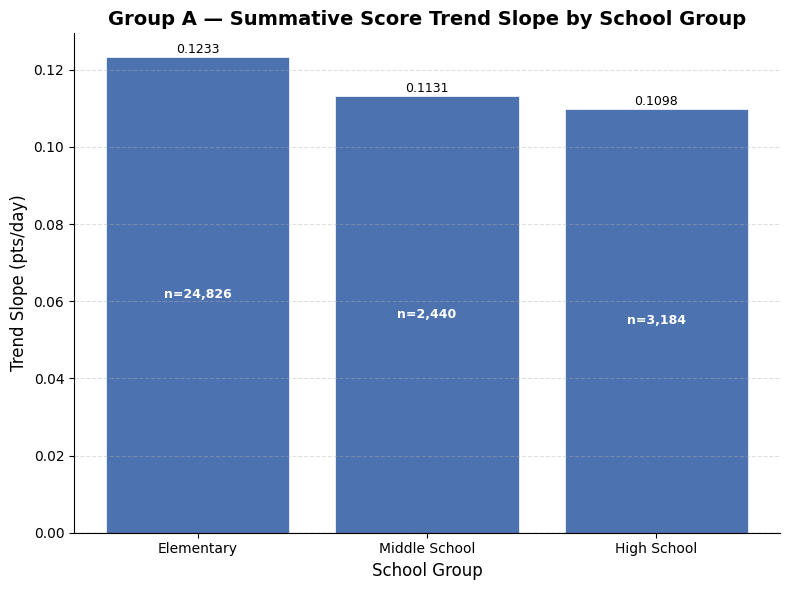

Saved: plots/group_a_slope_by_school_group.png


In [11]:
# --- Slope bar chart by school group ---
group_slopes = {}
group_counts = {}
for group in group_order:
    group_data = scatter_df_grouped[scatter_df_grouped["SchoolGroup"] == group]
    x = group_data["days"].values
    y = group_data["score"].values
    if len(x) < 2:
        continue
    slope, _, _, _, _ = stats.linregress(x, y)
    group_slopes[group] = slope
    group_counts[group] = group_data["SSID"].nunique()

slopes = [group_slopes[g] for g in group_order]
counts = [group_counts[g] for g in group_order]

fig, ax = plt.subplots(figsize=(8, 6))

colors = ["#4C72B0" if s >= 0 else "#C44E52" for s in slopes]
bars = ax.bar(group_order, slopes, color=colors, edgecolor="white", linewidth=0.5)

for bar, slope in zip(bars, slopes):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + (0.0002 if slope >= 0 else -0.0002),
        f"{slope:.4f}",
        ha="center", va="bottom" if slope >= 0 else "top", fontsize=9
    )

for bar, count, slope in zip(bars, counts, slopes):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() / 2,
        f"n={count:,}",
        ha="center", va="center", fontsize=9,
        color="white", fontweight="bold"
    )

ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
ax.set_xlabel("School Group", fontsize=12)
ax.set_ylabel("Trend Slope (pts/day)", fontsize=12)
ax.set_title("Group A — Summative Score Trend Slope by School Group", fontsize=14, fontweight="bold")
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("plots/group_a_slope_by_school_group.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: plots/group_a_slope_by_school_group.png")

# Break out by CALPADSSchoolCode

In [ ]:
# --- Rebuild scatter dataset including CALPADSSchoolCode from summative ELPAC ---
records = []
for year_num, df in summative_dfs.items():
    df_group = df[df["SSID"].isin(complete_ssids)].dropna(
        subset=["OverallScaleScore", "TestStartDate"]
    )
    for _, row in df_group.iterrows():
        ssid = row["SSID"]
        if ssid in first_initial_date:
            days = (row["TestStartDate"] - first_initial_date[ssid]).days
            records.append({
                "SSID": ssid,
                "days": days,
                "score": row["OverallScaleScore"],
                "CALPADSSchoolCode": row["CALPADSSchoolCode"]
            })

scatter_df = pd.DataFrame(records)

# --- Apply filters ---
scatter_df = scatter_df[(scatter_df["days"] > 0) & (scatter_df["score"] > 1000)]
print(f"Filtered scatter points (x > 0, y > 1000): {len(scatter_df):,}")

# --- Merge in grade level ---
scatter_df = scatter_df.merge(
    enrollment_a[["SSID", "GradeLevelCode"]].dropna(),
    on="SSID", how="left"
)

# --- Global y-axis max ---
y_max = scatter_df["score"].max() * 1.10
print(f"Global max score: {scatter_df['score'].max():.1f}, y-axis ceiling: {y_max:.1f}")

# --- Unique school codes ---
school_codes = sorted(scatter_df["CALPADSSchoolCode"].dropna().unique())
print(f"Unique school codes: {len(school_codes)}")

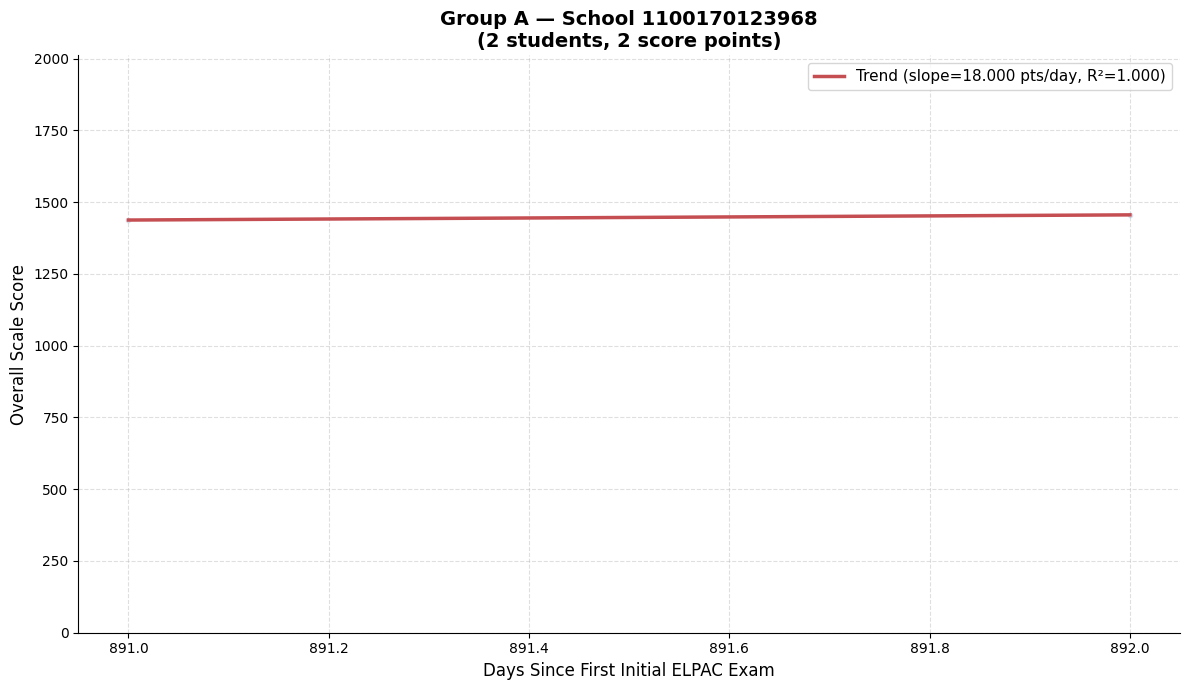

Saved: plots/group_a_school_1100170123968_scatter.png


ValueError: Cannot calculate a linear regression if all x values are identical

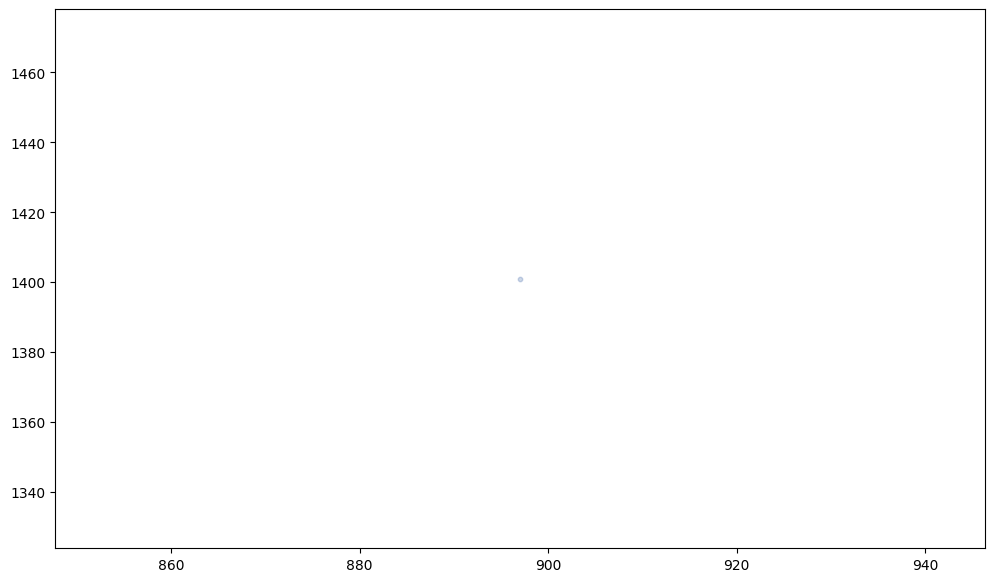

In [6]:
# --- One scatter plot per school code ---
os.makedirs("plots", exist_ok=True)

for school in school_codes:
    school_data = scatter_df[scatter_df["CALPADSSchoolCode"] == school]
    x = school_data["days"].values
    y = school_data["score"].values

    if len(x) < 2:
        print(f"Skipping school {school} — insufficient data ({len(x)} points)")
        continue

    fig, ax = plt.subplots(figsize=(12, 7))

    ax.scatter(x, y, color="#4C72B0", alpha=0.15, s=10, zorder=2)

    slope, intercept, r_value, _, _ = stats.linregress(x, y)
    trend_x = np.linspace(x.min(), x.max(), 300)
    trend_y = slope * trend_x + intercept
    r_squared = r_value ** 2
    ax.plot(trend_x, trend_y, color="#C44E52", linewidth=2.5, zorder=3,
            label=f"Trend (slope={slope:.3f} pts/day, R²={r_squared:.3f})")

    ax.set_ylim(0, y_max)
    ax.set_xlabel("Days Since First Initial ELPAC Exam", fontsize=12)
    ax.set_ylabel("Overall Scale Score", fontsize=12)
    ax.set_title(f"Group A — School {school}\n"
                 f"({school_data['SSID'].nunique():,} students, {len(x):,} score points)",
                 fontsize=14, fontweight="bold")
    ax.legend(fontsize=11)
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.spines[["top", "right"]].set_visible(False)

    plt.tight_layout()
    plt.savefig(f"plots/group_a_school_{school}_scatter.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: plots/group_a_school_{school}_scatter.png")

In [7]:
# --- Slope bar chart by school code ---
school_slopes = {}
school_counts = {}
for school in school_codes:
    school_data = scatter_df[scatter_df["CALPADSSchoolCode"] == school]
    x = school_data["days"].values
    y = school_data["score"].values
    if len(x) < 2:
        continue
    slope, _, _, _, _ = stats.linregress(x, y)
    school_slopes[school] = slope
    school_counts[school] = school_data["SSID"].nunique()

schools = list(school_slopes.keys())
slopes = list(school_slopes.values())
counts = [school_counts[s] for s in schools]

fig, ax = plt.subplots(figsize=(max(12, len(schools) * 0.6), 6))

colors = ["#4C72B0" if s >= 0 else "#C44E52" for s in slopes]
bars = ax.bar(range(len(schools)), slopes, color=colors, edgecolor="white", linewidth=0.5)

# Slope label on top/bottom of each bar
for bar, slope in zip(bars, slopes):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + (0.0002 if slope >= 0 else -0.0002),
        f"{slope:.4f}",
        ha="center",
        va="bottom" if slope >= 0 else "top",
        fontsize=7
    )

# Student count inside each bar
for bar, count, slope in zip(bars, counts, slopes):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() / 2,
        f"n={count:,}",
        ha="center",
        va="center",
        fontsize=7,
        color="white",
        fontweight="bold"
    )

ax.set_xticks(range(len(schools)))
ax.set_xticklabels(schools, rotation=45, ha="right", fontsize=8)
ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
ax.set_xlabel("CALPADS School Code", fontsize=12)
ax.set_ylabel("Trend Slope (pts/day)", fontsize=12)
ax.set_title("Group A — Summative Score Trend Slope by School Code", fontsize=14, fontweight="bold")
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("plots/group_a_slope_by_school.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: plots/group_a_slope_by_school.png")

ValueError: Cannot calculate a linear regression if all x values are identical

In [8]:
# --- Histogram of student counts per school code ---
school_student_counts = (
    scatter_df.groupby("CALPADSSchoolCode")["SSID"]
    .nunique()
    .sort_values(ascending=False)
    .reset_index()
)
school_student_counts.columns = ["CALPADSSchoolCode", "StudentCount"]

print(f"Total schools: {len(school_student_counts)}")
print(school_student_counts.to_string(index=False))

fig, ax = plt.subplots(figsize=(max(12, len(school_student_counts) * 0.6), 6))

bars = ax.bar(
    range(len(school_student_counts)),
    school_student_counts["StudentCount"],
    color="#4C72B0", edgecolor="white", linewidth=0.5, alpha=0.9
)

# Student count label on top of each bar
for bar, count in zip(bars, school_student_counts["StudentCount"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.3,
        f"{count:,}",
        ha="center", va="bottom", fontsize=7
    )

ax.set_xticks(range(len(school_student_counts)))
ax.set_xticklabels(school_student_counts["CALPADSSchoolCode"], rotation=45, ha="right", fontsize=8)
ax.set_xlabel("CALPADS School Code", fontsize=12)
ax.set_ylabel("Number of Students", fontsize=12)
ax.set_title("Group A — Student Count by School Code", fontsize=14, fontweight="bold")
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("plots/group_a_students_by_school.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: plots/group_a_students_by_school.png")

Total schools: 2500
 CALPADSSchoolCode  StudentCount
    34765050101766           235
    10751276006985           179
    10751276006969           168
    37679916037725           149
    37681303731692           132
    34765056066682           128
    34674476034524           128
    34674476034623           127
    34674476034920           127
    10751270129163           116
    37679916037683           112
    37679916037568           111
    37679916037584           104
     1611920138339           102
    34765056033435           101
    21654586024830            98
     7617546004154            97
     1612590115204            96
    37679916037592            96
    19647331996115            93
     1612590111476            89
    19647331930924            89
    50711676052633            89
    34674476034490            88
    21654586024756            87
     1612590125716            86
    19647336019715            85
    19647336019640            84
    38684780119875     

Saved: plots/group_a_students_by_school.png
